# Setup

In [59]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().resolve().parent))

import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

from training.models import get_lasenet_for_continuous_output

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Generate Synthetic dataset

Generate data from an RLF model described in the paper.

## Generate task sequences

In [2]:
from simulation.sequence_generator import create_stim_sequence

# Experimental task strcture.
pval = 1
num_blocks = 12
num_stim = 6
min_switches = [1200, 1200]
iter_per_stimuli = 13
num_actions = 3

all_seq = []
stim_iter_per_block = iter_per_stimuli - 1
for _ in range(10):
    one_seq = []
    i = 0
    while i < num_blocks:
        bseq = create_stim_sequence(stim_iter_per_block, num_stim)
        unique_values, counts = np.unique(bseq, return_counts=True)
        wrong_seq = not np.all(counts == (stim_iter_per_block + 1))
        if wrong_seq:
            continue

        i += 1
        one_seq.append(bseq)

    all_seq.append(one_seq)

## Simulate the RLF model performing on the task

In [3]:
from simulation.rlf import generate_rlf_parameters
from simulation.sim_agent import simulate_agent
from concurrent.futures import ProcessPoolExecutor
import tqdm

model_name = "rlf"
N_AGENTS = 100  # number of agents - change to your own needs

parameters_dist = generate_rlf_parameters(N_AGENTS)
with ProcessPoolExecutor(max_workers=2) as executor:
    futures = [
        executor.submit(
            simulate_agent,
            a,
            pval,
            num_blocks,
            [num_stim, num_stim],
            min_switches,
            iter_per_stimuli,
            num_actions,
            all_seq[a % len(all_seq)],
            params_dist=parameters_dist[a],
        )
        for a in range(N_AGENTS)
    ]
    train_data_list = [future.result() for future in tqdm.tqdm(futures)]

train_df = pd.concat(train_data_list)

train_df.head(3)

100%|██████████| 100/100 [00:03<00:00, 25.66it/s]


,actions,stimuli,correct_actions,rewards,trials,isswitch,iscorrectaction,rpe_history,alpha,neg_alpha,bias,beta,phi,stickiness,agentid,eps,delay_since_last_stimuli,block_no,condition,set_size
0,1,0,2,0,0,0,0,-0.333333,0.755114,0.755114,1,11.210977,0.13218,0.040616,0,0,0,0,1,6
1,1,1,1,1,1,0,1,0.666667,0.755114,0.755114,1,11.210977,0.13218,0.040616,0,0,0,0,1,6
2,0,2,0,1,2,0,1,0.666667,0.755114,0.755114,1,11.210977,0.13218,0.040616,0,0,0,0,1,6


# Validate Synthetic dataset

/var/folders/6y/khb9drcn0p373bwf72szrzvm0000gn/T/ipykernel_22133/3607247852.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res.groupby(["agentid", f"{key}_cat", "phi group"])[["rewards"]]


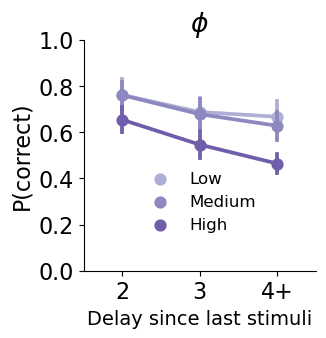

In [9]:
key = "delay_since_last_stimuli"
res = train_df[train_df.delay_since_last_stimuli > 1].copy()
# Create 5 equal-width bins for bias values
res["phi group"] = pd.qcut(res["phi"], q=3, labels=["Low", "Medium", "High"])
res[f"{key}_cat"] = res[key].apply(lambda x: "4+" if x > 4 else str(x))

res = (
    res.groupby(["agentid", f"{key}_cat", "phi group"])[["rewards"]]
    .mean()
    .reset_index()
)

plt.rcParams.update({"font.size": 16})
fig, ax = plt.subplots(1, 1, figsize=(3, 3), sharey=True)
ax = sns.pointplot(
    data=res,
    x=f"{key}_cat",
    y="rewards",
    order=["2", "3", "4+"],
    hue="phi group",
    palette=sns.color_palette("Purples")[2:],
    ax=ax,
    ci=95,
)
ax.set_ylabel("P(correct)")
ax.set_yticks(np.round(np.arange(0, 1.2, 0.2), 2))
ax.set_title(r"$\phi$")
ax.set_xlabel("Delay since last stimuli", fontsize=14)
# sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), fontsize=12)
sns.move_legend(
    ax,
    "lower center",
    bbox_to_anchor=(0.5, 0.1),
    ncol=1,
    fontsize=12,
    markerscale=1,
    frameon=False,
    title=None,
)
sns.despine()
sns.despine()

# Extract input features and output labels

## Preprocess features

In [4]:
from utils.feature_utils import (
    extract_features_blockless,
)

# Extract features in RL based models. Skip this part if it is not relevant to your task or model.
has_switches = train_df.isswitch.nunique() == 2
td_iter = train_df.copy()
td_iter["delay_since_last_stimuli"] = train_df["delay_since_last_stimuli"].to_list()

if has_switches:
    td_iter.loc[td_iter.trials == 0, "isswitch"] = 1
else:
    td_iter["isswitch"] = td_iter["trials"].apply(lambda x: 1 if x == 0 else 0)

td_iter["prev_action"] = (
    train_df.groupby(["agentid", "block_no"])["actions"]
    .shift(1)
    .fillna(-1)
    .astype(int)
    .to_list()
)

## Extract features and labels

In [51]:
def get_features_labels(data, feature_list):
    n_block = data["block_no"].nunique()
    n_trial = data["trials"].nunique()

    n_agent = data["agentid"].nunique()
    qv = np.array(data["rewards"] - data["rpe_history"])
    labels = qv.astype(np.float32).reshape((n_agent, n_block * n_trial))

    features = extract_features_blockless(data, feature_list, [])
    print(features.shape)
    return features, labels


feature_list = [
    "rewards",
    "delay_since_last_stimuli",
    "actions",
    "prev_action",
    "isswitch",
    "stimuli",
]
features, train_labels = get_features_labels(td_iter, feature_list)

(100, 936, 6)


## Split training and validation dataset

In [7]:
X_train, X_test, qv_train, qv_test = train_test_split(
    features, train_labels, test_size=0.1, random_state=33
)
print(
    X_train.shape,
    X_test.shape,
    qv_train.shape,
    qv_test.shape,
)

(90, 936, 6) (10, 936, 6) (90, 936) (10, 936)


# Train a neural estimator

In [9]:
### CHANGE ME
# this is a small network for demonstration purpose
# you can change the network architecture to your own needs
batch_size = 32
units = 32
dropout = 0.065
dropout1 = 0.1929
dropout2 = 0.113
learning_rate = 0.3
###

tf.keras.utils.set_random_seed(11)
identifier = (
    f"lasenet_B{batch_size}_U{units}_D{dropout}_D{dropout1}_D{dropout2}_{learning_rate}"
)
param_settings = {
    "feature_dim": X_train.shape[-1],
    "discrete_output_dim": 0,
    "continuous_output_dim": 1,
    "units": units,
    "dropout": dropout,
    "dropout1": dropout1,
    "dropout2": dropout2,
    "learning_rate": learning_rate,
}
best_model = get_lasenet_for_continuous_output(param_settings)

print(identifier)

lasenet_B32_U32_D0.065_D0.1929_D0.113_0.3


In [10]:
callbacks = [EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)]

start = time.time()
history = best_model.fit(
    X_train,
    y=qv_train,
    batch_size=batch_size,
    epochs=10, # CHANGE ME to higher number e.g., 600
    verbose=2,
    callbacks=callbacks,
    validation_data=(X_test, qv_test),
)

end = time.time()

Epoch 1/10


2026-11-01 11:35:02.559935: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


3/3 - 3s - 1s/step - loss: 121.9142 - val_loss: 0.3766
Epoch 2/10
3/3 - 1s - 192ms/step - loss: 0.5417 - val_loss: 0.8578
Epoch 3/10
3/3 - 1s - 187ms/step - loss: 0.9703 - val_loss: 1.1475
Epoch 4/10
3/3 - 1s - 170ms/step - loss: 1.1908 - val_loss: 1.2185
Epoch 5/10
3/3 - 0s - 166ms/step - loss: 1.2027 - val_loss: 1.1145
Epoch 6/10
3/3 - 1s - 169ms/step - loss: 1.0598 - val_loss: 0.9039
Epoch 7/10
3/3 - 1s - 174ms/step - loss: 0.8320 - val_loss: 0.6551
Epoch 8/10
3/3 - 1s - 180ms/step - loss: 0.5841 - val_loss: 0.4226
Epoch 9/10
3/3 - 1s - 184ms/step - loss: 0.3645 - val_loss: 0.2402
Epoch 10/10
3/3 - 1s - 167ms/step - loss: 0.2002 - val_loss: 0.1204


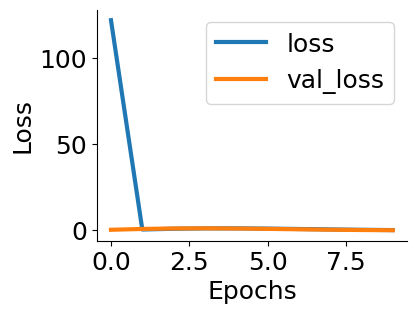

In [11]:
result = pd.DataFrame(history.history)

plt.rcParams.update({'font.size': 18})
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(4, 3))
ax.plot(result.index, result["loss"], linewidth=3, label="loss")
ax.plot(result.index, result["val_loss"], linewidth=3, label="val_loss")
ax.legend()
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')
sns.despine()

# Evaludate neural estimators

## Load test dataset

In [42]:
test_df = pd.read_csv("./data/rlf_6s3a/rand500_st11_500a_12b_78t_rlf.csv")

## Extract test features

In [52]:
test_iter = test_df.copy()
test_iter["delay_since_last_stimuli"] = test_df["delay_since_last_stimuli"].to_list()

if has_switches:
    test_iter.loc[test_iter.trials == 0, "isswitch"] = 1
else:
    test_iter["isswitch"] = test_iter["trials"].apply(lambda x: 1 if x == 0 else 0)

test_iter["prev_action"] = (
    test_df.groupby(["agentid", "block_no"])["actions"]
    .shift(1)
    .fillna(-1)
    .astype(int)
    .to_list()
)

test_features, test_labels = get_features_labels(test_iter, feature_list)

(500, 936, 6)


## Inference

In [58]:
# LOAD trained LASENET 
model_name = "lasenet_s123_RLF-6S3A_r-d-a-p-i-s_A27000_936t_B128_U256_D0.097_D0.013_D0.011_0.000696_model.keras"
gru_model = tf.keras.models.load_model(f"./pretrained/{model_name}", compile=True)

In [53]:
output_tokens = gru_model.predict(test_features)

num_test_agents = test_iter["agentid"].nunique()
n_trial = test_iter["trials"].nunique()
n_block = test_iter["block_no"].nunique()

pred_q = output_tokens.reshape(num_test_agents, n_trial * n_block)
print(pred_q.shape)

2026-11-02 14:20:28.058532: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 358ms/step
(500, 936)


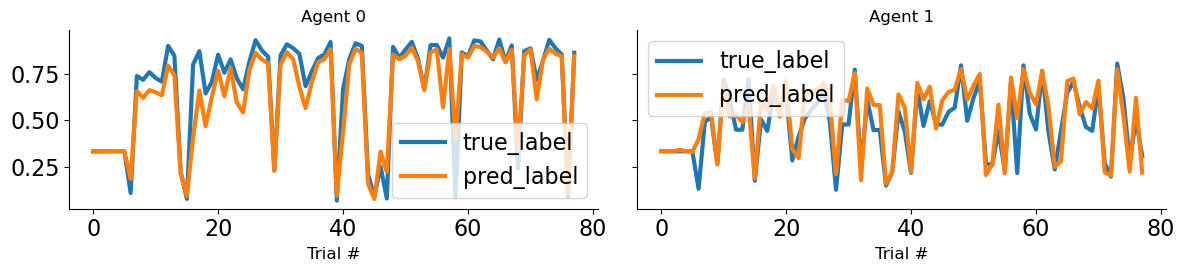

In [54]:
def plot_time_series(axes, y_true, y_pred, max_trial):
    for idx, ax in enumerate(axes.flat):
        result = pd.DataFrame(
            {
                "true_label": y_true[idx][:max_trial],
                "pred_label": y_pred[idx][:max_trial],
            }
        )
        ax.plot(result.index, result["true_label"], linewidth=3, label="true_label")
        ax.plot(result.index, result["pred_label"], linewidth=3, label="pred_label")
        ax.legend()
        ax.set_xlabel("Trial #", fontsize=12)
        ax.set_title(f"Agent {idx}", fontsize=12)
    return axes


n_cols = 2
fig, axes = plt.subplots(
    nrows=1, ncols=n_cols, figsize=(n_cols * 6, 1 * 3), sharey=True, sharex=True
)
max_trial = n_trial * 1
axes = plot_time_series(axes, test_labels, pred_q, max_trial)

sns.despine()
fig.tight_layout()

## Permutation test

In [55]:
from utils.feature_importance_utils import (
    permutation_importance_global_sequence,
)

# Generate sample_weight array: 0 for NaN values in test_labels, 1 otherwise
# For keras RNNs, sample_weight usually shape is (batch, timestep)
test_labels_dim = np.expand_dims(test_labels, axis=-1)

# 2. Create the weight mask (1 for valid, 0 for NaN)
sample_weight = (~np.isnan(test_labels_dim)).astype(np.float32)
sample_weight = np.squeeze(sample_weight, axis=-1) 

# 3. Fill NaNs with an absurd out-of-bounds dummy value.
# The sample_weight will multiply the loss for these steps by 0,
# completely erasing this -9999.0 from the final calculation.
test_labels_clean = np.nan_to_num(test_labels_dim, nan=-9999.0)
print(sample_weight.shape, test_labels_clean.shape)

ranking = permutation_importance_global_sequence(
    model=gru_model,     # already trained once
    X_val=test_features,
    y_val=test_labels_clean,
    feature_names=feature_list,
    n_repeats=3,
    batch_size=64,
    sample_weight=sample_weight,  # put mask here if you use padded timesteps
    shuffle_mode="within_sample",
    random_state=11
)

print(ranking)

(500, 936) (500, 936, 1)


2026-11-02 14:20:38.064142: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


Baseline loss: 0.004857237916439772
Permutation feature rewards


2026-11-02 14:20:44.276104: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


Permutation loss: 0.05367869511246681


2026-11-02 14:20:50.796374: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


... (29 outputs left out)

2026-11-02 14:22:35.797358: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


Permutation loss: 0.004881970584392548


2026-11-02 14:22:42.822433: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


Permutation loss: 0.004899578634649515
                    feature  importance_mean  importance_std  baseline_loss  \
0                   rewards         0.049365        0.000388       0.004857   
1  delay_since_last_stimuli         0.025910        0.000443       0.004857   
2                   actions         0.007826        0.000069       0.004857   
3               prev_action         0.006008        0.000024       0.004857   
4                  isswitch         0.001932        0.000006       0.004857   
5                   stimuli         0.000022        0.000018       0.004857   

   permuted_loss_mean  
0            0.054222  
1            0.030768  
2            0.012683  
3            0.010866  
4            0.006789  
5            0.004879  


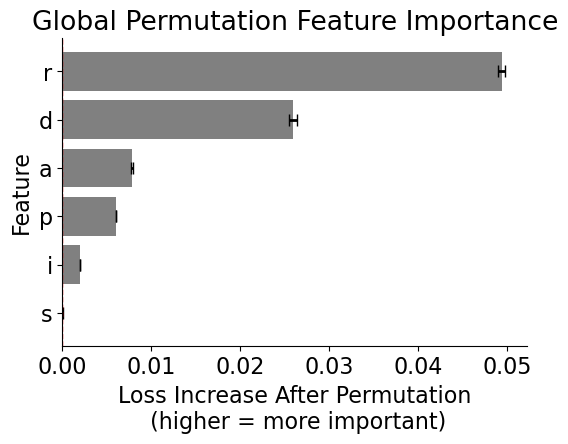

In [57]:
plt.rcParams.update({"font.size": 16})

fig, ax = plt.subplots(figsize=(6, 4))
ax = sns.barplot(
    data=ranking,
    x="importance_mean",
    y="feature",
    color="grey",
    ax=ax,
)
# add error bars if present
if "importance_std" in ranking.columns:
    ax.errorbar(
        x=ranking["importance_mean"],
        y=range(len(ranking)),
        xerr=ranking["importance_std"],
        fmt="none",
        ecolor="black",
        capsize=4,
        lw=2
    )
ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_title(f"Global Permutation Feature Importance") # ({k}% missing)")
ax.set_xlabel("Loss Increase After Permutation\n (higher = more important)")
short_labels = [l.get_text()[:1] for l in ax.get_yticklabels()]
ax.set_yticklabels(short_labels, rotation=0)
ax.set_ylabel("Feature")
sns.despine(ax=ax)